# EDA para los modelos clasificador

## Preparación y carga de datos

In [7]:
%pip -q install "kagglehub==1.0.3"

from pathlib import Path
from google.colab import drive
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount("/content/drive")

BASE_LOCAL = Path("/content/proyecto_aves")
BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
DIR_EDA = BASE_DRIVE / "experiments/classifier/EDA_v1"
DATASET = "santiagocorrea802/dataset-proyecto"
DIR_EDA.mkdir(parents=True, exist_ok=True)
BASE_LOCAL.mkdir(parents=True, exist_ok=True)

print("Resultados:", DIR_EDA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/EDA_v1


## Cargar manifest

In [8]:
def leer_manifest(nombre):
    ruta = kagglehub.dataset_download(DATASET, path=f"DATASET_PROYECTO/metadata/{nombre}", output_dir=str(BASE_LOCAL))
    return pd.read_csv(ruta)

clasificador = leer_manifest("classifier_manifest.csv")
grabaciones = leer_manifest("recordings_manifest.csv")
especies = leer_manifest("target_species.csv")
splits = pd.read_csv(BASE_DRIVE / "splits/recording_split_seed0.csv")

assert clasificador["event_id"].is_unique
assert splits["recording_uid"].is_unique
assert set(clasificador["class_code"]) == set(range(31))
assert clasificador.loc[clasificador["class_code"] == 0, "class_label"].eq("OTHER_SPECIES").all()

datos = clasificador.merge(splits[["recording_uid", "split"]], on="recording_uid", validate="many_to_one")
assert datos["split"].notna().all()

datos = datos.loc[datos["split"].isin(["train", "validation"])].copy()

resumen = datos.groupby("split").agg(
    eventos=("event_id", "size"),
    grabaciones=("recording_uid", "nunique"),
    clases=("class_code", "nunique")
)

print("Eventos clasificador corpus:", len(clasificador))
print("Especies objetivo:", len(especies))
display(resumen)

Eventos clasificador corpus: 25589
Especies objetivo: 30


,eventos,grabaciones,clases
split,,,
train,17352,565,31
validation,3631,128,31


## Distribución de clases

In [9]:
clases = clasificador[["class_code", "class_label"]].drop_duplicates().sort_values("class_code").reset_index(drop=True)
conteos = datos.groupby(["class_code", "split"]).size().unstack(fill_value=0)
soporte = datos.groupby(["class_code", "split"])["recording_uid"].nunique().unstack(fill_value=0)
for split in ("train", "validation"):
    clases[f"{split}_eventos"] = clases["class_code"].map(conteos.get(split, pd.Series(dtype=int))).fillna(0).astype(int)
    clases[f"{split}_grabaciones"] = clases["class_code"].map(soporte.get(split, pd.Series(dtype=int))).fillna(0).astype(int)

clases.to_csv(DIR_EDA / "soporte_clases.csv", index=False)
print("Clases sin eventos train:", int((clases["train_eventos"] == 0).sum()))
print("Clases sin eventos validation:", int((clases["validation_eventos"] == 0).sum()))
print("Clases con menos de 5 grabaciones train:", int((clases["train_grabaciones"] < 5).sum()))
display(clases)

Clases sin eventos train: 0
Clases sin eventos validation: 0
Clases con menos de 5 grabaciones train: 0


,class_code,class_label,train_eventos,train_grabaciones,validation_eventos,validation_grabaciones
0,0,OTHER_SPECIES,8077,468,1442,93
1,1,arremon brunneinucha,504,44,81,10
2,2,atlapetes schistaceus,178,20,46,7
3,3,attila spadiceus,122,36,34,6
4,4,camptostoma obsoletum,178,13,53,4
5,5,campylorhynchus turdinus,741,20,151,5
6,6,cantorchilus leucotis,620,32,45,4
7,7,colibri cyanotus,313,34,120,10
8,8,crypturellus cinereus,411,120,112,25
9,9,crypturellus soui,166,17,23,5


**Resultados:** Todas las clases tienen ejemplos en entrenamiento y validación, y ninguna cuenta con menos de 5 grabaciones de entrenamiento. Sin embargo, algunas presentan una representación muy limitada en validación, como *dendrocolaptes certhia* (1 evento) y *empidonax virescens* (3 eventos), lo que dificulta obtener métricas fiables para estas especies

## Visualizar desbalance

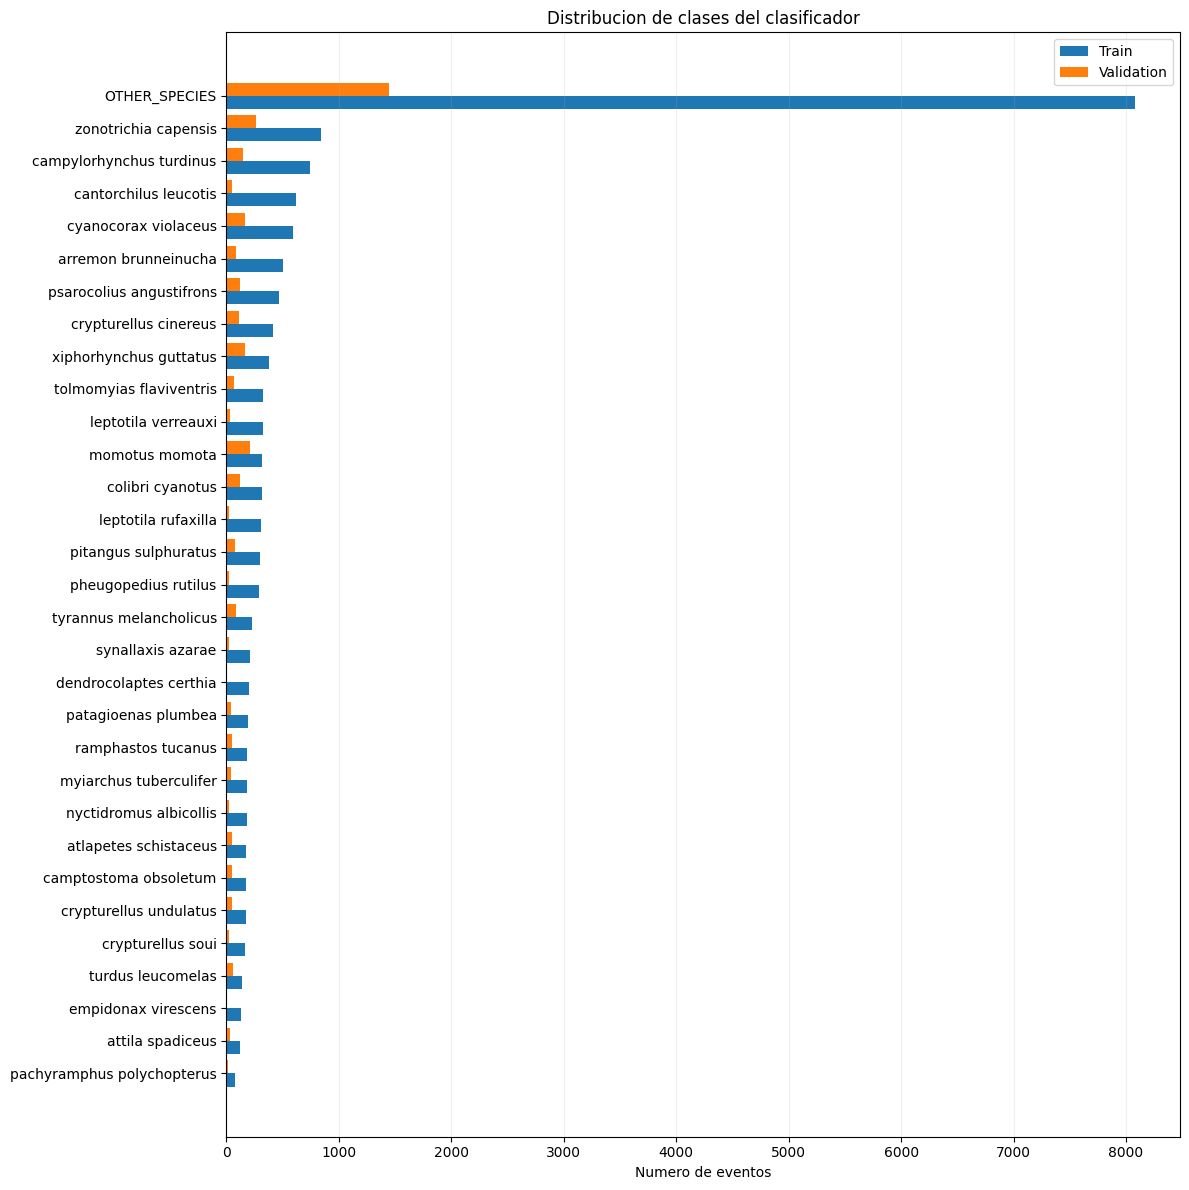

OTHER_SPECIES en train: 46.55%
OTHER_SPECIES en validation: 39.71%


In [10]:
orden = clases.sort_values("train_eventos")
y = np.arange(len(orden))

fig, ax = plt.subplots(figsize=(12, 12))
ax.barh(y - 0.2, orden["train_eventos"], height=0.4, label="Train")
ax.barh(y + 0.2, orden["validation_eventos"], height=0.4, label="Validation")
ax.set_yticks(y)
ax.set_yticklabels(orden["class_label"])
ax.set_xlabel("Numero de eventos")
ax.set_title("Distribucion de clases del clasificador")
ax.legend()
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

for split in ("train", "validation"):
    grupo = datos.loc[datos["split"] == split]
    porcentaje = 100 * grupo["class_code"].eq(0).mean()
    print(f"OTHER_SPECIES en {split}: {porcentaje:.2f}%")

**Resultados:** Se identificó un desbalance considerable entre las clases. OTHER_SPECIES representa el 46,5 % de los eventos de entrenamiento y el 39,7 % de validación, mientras que varias especies tienen menos de 200 ejemplos. Será necesario considerar este desbalance durante el entrenamiento y la evaluación.

## Duración y rango frecuencial

Necesitamos decidir cómo recortar las vocalizaciones para alimentar EfficientNet-B0 y Swin-T

Todavía no asumiremos que todas las vocalizaciones pueden representarse adecuadamente mediante recortes de una duración fija

In [11]:
datos["duracion_s"] = datos["t_max"] - datos["t_min"]
datos["ancho_hz"] = datos["f_max"] - datos["f_min"]

percentiles = datos.groupby("split")[["duracion_s", "ancho_hz"]].quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
display(percentiles.round(3))

for split, grupo in datos.groupby("split"):
    print(f"{split} | Duracion menor a 0.25s: {(grupo['duracion_s'] < 0.25).mean():.2%}")
    print(f"{split} | Duracion mayor a 8s: {(grupo['duracion_s'] > 8).mean():.2%}")
    print(f"{split} | Frecuencia minima: {grupo['f_min'].min():.1f} Hz")
    print(f"{split} | Frecuencia maxima: {grupo['f_max'].max():.1f} Hz")

print("Eventos con duracion invalida:", int((datos["duracion_s"] <= 0).sum()))
print("Eventos con banda invalida:", int((datos["ancho_hz"] <= 0).sum()))

duracion_s   ancho_hz
split                                 
train      0.10       0.399    595.000
           0.25       0.737   1071.000
           0.50       1.500   2064.000
           0.75       2.800   3553.800
           0.90       6.700   6070.258
           0.99      41.498  13082.402
validation 0.10       0.400    582.700
           0.25       0.721    982.100
           0.50       1.546   1905.000
           0.75       2.903   3558.500
           0.90       6.524   5591.800
           0.99      51.680   9820.090

train | Duracion menor a 0.25s: 4.64%
train | Duracion mayor a 8s: 7.79%
train | Frecuencia minima: 0.0 Hz
train | Frecuencia maxima: 16000.0 Hz
validation | Duracion menor a 0.25s: 4.05%
validation | Duracion mayor a 8s: 8.45%
validation | Frecuencia minima: 0.0 Hz
validation | Frecuencia maxima: 16000.0 Hz
Eventos con duracion invalida: 0
Eventos con banda invalida: 0


**Resultados:** La duración mediana de los eventos es de aproximadamente 1,5 segundos y el 90 % no supera los 6,7 segundos. Sin embargo, cerca del 8 % supera los 8 segundos, con valores extremos mayores de 40 segundos. El ancho de banda mediano ronda los 2 kHz. Esta variabilidad deberá considerarse al definir los recortes acústicos.

## Distribución por fuente y concentración de ejemplos

Nuestros datos vienen de cuatro fuentes diferentes, queremos evitar que el clasificador aprenda características de un lugar o una grabadora en vez de características acústicas de la especie

In [12]:
fuentes = datos.groupby(["split", "dataset"]).agg(eventos=("event_id", "size"), grabaciones=("recording_uid", "nunique"), clases=("class_code", "nunique")).reset_index()
display(fuentes)
mayores = (datos.loc[datos["split"] == "train"].groupby(["class_code", "recording_uid"]).size().groupby(level=0).max())
concentracion = clases[["class_code", "class_label", "train_eventos", "train_grabaciones"]].copy()
concentracion["mayor_grabacion_pct"] = 100 * concentracion["class_code"].map(mayores) / concentracion["train_eventos"].replace(0, np.nan)
print("Clases mas concentradas en una sola grabacion")
display(concentracion.sort_values("mayor_grabacion_pct", ascending=False).head(10).round(2))

fuentes.to_csv(DIR_EDA / "distribucion_fuentes.csv", index=False)
concentracion.to_csv(DIR_EDA / "concentracion_grabaciones.csv", index=False)

,split,dataset,eventos,grabaciones,clases
0,train,Col-CR,2106,23,11
1,train,Peru,4011,14,15
2,train,PteroSet,4771,254,20
3,train,WABAD-CO,6464,274,22
4,validation,Col-CR,486,5,6
5,validation,Peru,938,3,13
6,validation,PteroSet,822,61,14
7,validation,WABAD-CO,1385,59,21


Clases mas concentradas en una sola grabacion


,class_code,class_label,train_eventos,train_grabaciones,mayor_grabacion_pct
15,15,leptotila verreauxi,327,21,53.21
10,10,crypturellus undulatus,172,44,52.91
12,12,dendrocolaptes certhia,200,13,51.00
14,14,leptotila rufaxilla,304,10,46.71
17,17,myiarchus tuberculifer,186,21,36.02
30,30,zonotrichia capensis,843,39,30.96
1,1,arremon brunneinucha,504,44,30.16
29,29,xiphorhynchus guttatus,375,16,22.67
13,13,empidonax virescens,128,12,22.66
20,20,patagioenas plumbea,192,14,20.31


**Resultados:** Los eventos proceden de cuatro datasets con distribuciones diferentes. Se identificaron clases cuyos ejemplos están concentrados en pocas grabaciones; por ejemplo, una sola grabación reúne más del 50 % de los eventos de entrenamiento de algunas especies. Esto podría limitar la diversidad acústica y la capacidad de generalización del clasificador.

## duraciones extremas y anotaciones frecuenciales

In [13]:
train = datos.loc[datos["split"] == "train"].copy()
duraciones_fuente = train.groupby("dataset").agg(eventos=("event_id", "size"), duracion_mediana=("duracion_s", "median"), duracion_p90=("duracion_s", lambda x: x.quantile(0.90)), pct_mayor_8s=("duracion_s", lambda x: 100 * (x > 8).mean()), pct_fmin_0=("f_min", lambda x: 100 * (x == 0).mean()), pct_fmax_16000=("f_max", lambda x: 100 * (x == 16000).mean()))

print("Duraciones y limites frecuenciales por fuente")
display(duraciones_fuente.round(2))
duraciones_clase = train.groupby("class_label").agg(eventos=("event_id", "size"), duracion_mediana=("duracion_s", "median"), duracion_p90=("duracion_s", lambda x: x.quantile(0.90)), pct_mayor_8s=("duracion_s", lambda x: 100 * (x > 8).mean()))

print("Clases con mayor proporcion de eventos largos")
display(duraciones_clase.sort_values("pct_mayor_8s", ascending=False).head(12).round(2))

print("Eventos mas largos")
display(train.nlargest(10, "duracion_s")[["recording_uid", "dataset", "class_label", "t_min", "t_max", "duracion_s", "f_min", "f_max"]])

Duraciones y limites frecuenciales por fuente


,eventos,duracion_mediana,duracion_p90,pct_mayor_8s,pct_fmin_0,pct_fmax_16000
dataset,,,,,,
Col-CR,2106,2.10,11.65,16.43,3.37,0.00
Peru,4011,2.40,12.70,16.03,0.12,0.00
PteroSet,4771,0.90,5.21,4.72,4.97,4.63
WABAD-CO,6464,1.37,2.80,2.13,0.20,0.00


Clases con mayor proporcion de eventos largos


,eventos,duracion_mediana,duracion_p90,pct_mayor_8s
class_label,,,,
ramphastos tucanus,187,5.86,19.91,34.76
crypturellus soui,166,2.05,44.05,33.13
patagioenas plumbea,192,1.65,18.86,25.52
campylorhynchus turdinus,741,5.40,11.20,19.43
leptotila rufaxilla,304,0.90,26.24,14.14
synallaxis azarae,207,0.64,10.11,14.01
cantorchilus leucotis,620,1.50,10.52,13.23
momotus momota,318,0.60,8.49,10.69
zonotrichia capensis,843,1.76,6.16,7.59


Eventos mas largos


,recording_uid,dataset,class_label,t_min,t_max,duracion_s,f_min,f_max
15303,Peru::per_016_s02_20190131_100007z,Peru,OTHER_SPECIES,1767.7,3432.3,1664.6,2658.0,4603.0
13013,Peru::per_009_s02_20190120_100007z,Peru,OTHER_SPECIES,225.9,1315.4,1089.5,2770.0,4932.0
15474,Peru::per_017_s04_20190131_100007z,Peru,crypturellus soui,1314.9,1911.6,596.7,1666.0,2023.0
11843,Peru::per_007_s10_20190116_100007z,Peru,cantorchilus leucotis,1171.1,1760.0,588.9,1063.0,3976.0
13775,Peru::per_011_s05_20190120_100007z,Peru,cantorchilus leucotis,1197.0,1701.5,504.5,1150.0,3174.0
13822,Peru::per_011_s05_20190120_100007z,Peru,OTHER_SPECIES,1955.8,2399.7,443.9,6837.0,8754.0
13971,Peru::per_011_s05_20190120_100007z,Peru,ramphastos tucanus,1582.8,1969.9,387.1,952.0,3531.0
14353,Peru::per_013_s08_20190120_100007z,Peru,OTHER_SPECIES,2094.8,2478.8,384.0,392.0,5397.0
15287,Peru::per_016_s02_20190131_100007z,Peru,crypturellus soui,1273.1,1650.7,377.6,1309.0,1984.0
14473,Peru::per_014_s10_20190120_100007z,Peru,cantorchilus leucotis,1624.3,1980.1,355.8,1031.0,3730.0


**Resultados:** Las duraciones presentan diferencias importantes entre fuentes. Col-CR y Perú concentran las mayores proporciones de eventos superiores a 8 segundos (16,43 % y 16,03 %). Se identificaron anotaciones extremas en Perú, incluyendo intervalos superiores a 1.000 segundos, cuya interpretación debe revisarse antes de definir los recortes de entrenamiento.

## Relación entre especies y fuentes

Clases con mayor concentracion por fuente


,eventos_train,fuentes_train,fuente_dominante,pct_fuente_dominante
class_label,,,,
atlapetes schistaceus,178,1,WABAD-CO,100.00
cyanocorax violaceus,594,1,PteroSet,100.00
colibri cyanotus,313,1,WABAD-CO,100.00
empidonax virescens,128,1,WABAD-CO,100.00
turdus leucomelas,137,1,WABAD-CO,100.00
dendrocolaptes certhia,200,2,Peru,99.50
camptostoma obsoletum,178,2,WABAD-CO,99.44
xiphorhynchus guttatus,375,2,Peru,99.20
campylorhynchus turdinus,741,2,Peru,99.06


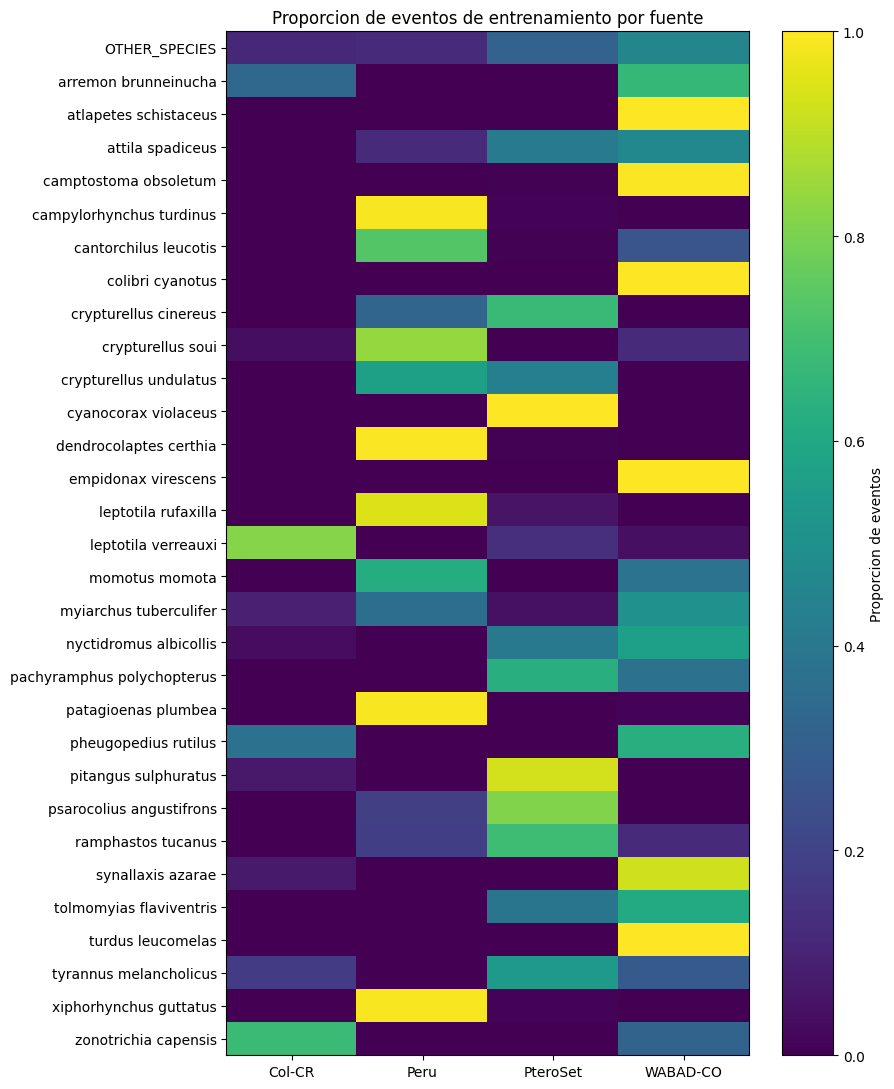

In [14]:
tabla_train = pd.crosstab(train["class_label"], train["dataset"])
proporciones = tabla_train.div(tabla_train.sum(axis=1), axis=0)
resumen_fuentes = pd.DataFrame({
    "eventos_train": tabla_train.sum(axis=1),
    "fuentes_train": tabla_train.gt(0).sum(axis=1),
    "fuente_dominante": proporciones.idxmax(axis=1),
    "pct_fuente_dominante": proporciones.max(axis=1) * 100
})

print("Clases con mayor concentracion por fuente")
display(resumen_fuentes.sort_values("pct_fuente_dominante", ascending=False).head(15).round(2))
fig, ax = plt.subplots(figsize=(9, 11))
imagen = ax.imshow(proporciones, aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(proporciones.columns)))
ax.set_xticklabels(proporciones.columns)
ax.set_yticks(range(len(proporciones.index)))
ax.set_yticklabels(proporciones.index)
ax.set_title("Proporcion de eventos de entrenamiento por fuente")
fig.colorbar(imagen, ax=ax, label="Proporcion de eventos")
plt.tight_layout()
plt.show()

**Resultados:** Se identificó una fuerte dependencia entre especies y fuentes de datos. Cinco especies aparecen exclusivamente en una fuente de entrenamiento y otras presentan concentraciones superiores al 98 %. Esta distribución podría favorecer el aprendizaje de características propias de las grabaciones, limitando la generalización del clasificador.

## Intervalos excesivamente largos

In [15]:
umbrales = [8, 30, 60, 300]
resumen_largos = train.groupby("dataset")["duracion_s"].agg(
    eventos="size",
    **{
        f"mayor_{limite}s": lambda x, limite=limite: int((x > limite).sum())
        for limite in umbrales
    }
)

display(resumen_largos)
largos = train.loc[train["duracion_s"] > 60].copy()
por_grabacion = dict(tuple(train.groupby("recording_uid")))
resultados_largos = []
for fila in largos.itertuples(index=False):
    grupo = por_grabacion[fila.recording_uid]
    otros = grupo.loc[(grupo["event_id"] != fila.event_id) & (grupo["class_code"] != fila.class_code)]
    solape_temporal = ((otros["t_min"] < fila.t_max) & (otros["t_max"] > fila.t_min))
    solape_frecuencial = ((otros["f_min"] < fila.f_max) & (otros["f_max"] > fila.f_min))

    resultados_largos.append({
        "event_id": fila.event_id,
        "dataset": fila.dataset,
        "class_label": fila.class_label,
        "duracion_s": fila.duracion_s,
        "otras_clases_solapadas": int((solape_temporal & solape_frecuencial).sum())
    })

revision_largos = pd.DataFrame(resultados_largos)
print("Eventos mayores de 60 segundos:", len(revision_largos))
if not revision_largos.empty:
    display(revision_largos.sort_values("duracion_s", ascending=False).head(20))
    revision_largos.to_csv(DIR_EDA / "revision_eventos_largos.csv", index=False)

,eventos,mayor_8s,mayor_30s,mayor_60s,mayor_300s
dataset,,,,,
Col-CR,2106,346,58,5,0
Peru,4011,643,184,82,13
PteroSet,4771,225,0,0,0
WABAD-CO,6464,138,28,0,0


Eventos mayores de 60 segundos: 87


,event_id,dataset,class_label,duracion_s,otras_clases_solapadas
74,Peru::13138,Peru,OTHER_SPECIES,1664.6,23
33,Peru::7465,Peru,OTHER_SPECIES,1089.5,10
79,Peru::13744,Peru,crypturellus soui,596.7,23
24,Peru::4874,Peru,cantorchilus leucotis,588.9,4
43,Peru::9123,Peru,cantorchilus leucotis,504.5,28
45,Peru::9278,Peru,OTHER_SPECIES,443.9,0
49,Peru::9630,Peru,ramphastos tucanus,387.1,22
58,Peru::10950,Peru,OTHER_SPECIES,384.0,14
71,Peru::13086,Peru,crypturellus soui,377.6,22
64,Peru::11385,Peru,cantorchilus leucotis,355.8,30


## Procedencia entre train y validation

In [16]:
soporte_fuentes = (datos.groupby(["class_label", "dataset", "split"]).size().unstack(fill_value=0).reset_index())
nuevas_fuentes = soporte_fuentes.loc[(soporte_fuentes["train"] == 0) & (soporte_fuentes["validation"] > 0)].copy()
resumen_nuevas = (nuevas_fuentes.groupby("class_label").agg(fuentes_nuevas=("dataset", "nunique"),eventos_validation=("validation", "sum")).sort_values("eventos_validation", ascending=False))
print("Especies con fuentes nuevas en validation:", len(resumen_nuevas))
print("Eventos de validation en fuentes no vistas:", int(nuevas_fuentes["validation"].sum()))
display(nuevas_fuentes[["class_label", "dataset", "validation"]])
display(resumen_nuevas)
nuevas_fuentes.to_csv(DIR_EDA / "fuentes_no_vistas_validation.csv", index=False)

Especies con fuentes nuevas en validation: 1
Eventos de validation en fuentes no vistas: 7


split,class_label,dataset,validation
51,pitangus sulphuratus,WABAD-CO,7


,fuentes_nuevas,eventos_validation
class_label,,
pitangus sulphuratus,1,7


**Resultados:** Se identificaron 87 anotaciones superiores a 60 segundos, de las cuales 82 pertenecen a Perú. Algunas superan los 1.000 segundos y presentan numerosos solapamientos con eventos de otras especies, por lo que requieren revisión antes de generar recortes para clasificación.

En cuanto a la distribución por fuentes, únicamente *pitangus sulphuratus* presenta eventos de validación en una fuente no representada para esa especie durante el entrenamiento (7 eventos de WABAD-CO). Aunque la mayoría de las combinaciones especie-fuente de validación están representadas en entrenamiento, persisten riesgos de sesgo y generalización debido a la concentración de ciertas especies en fuentes y grabaciones específicas.

## Recortes de 4 y 8 segundos

In [17]:
duraciones_audio = grabaciones.set_index("recording_uid")["duration_sec"]
resultados = []

for ventana_s in (4, 8):
    completos = []
    otras_clases = []
    otras_sin_extremos = []

    for uid, grupo in train.groupby("recording_uid"):
        inicio_evento = grupo["t_min"].to_numpy()
        fin_evento = grupo["t_max"].to_numpy()
        clases_evento = grupo["class_code"].to_numpy()
        duraciones = grupo["duracion_s"].to_numpy()

        duracion_audio = duraciones_audio.loc[uid]

        inicio = np.clip((inicio_evento + fin_evento) / 2 - ventana_s / 2, 0, max(duracion_audio - ventana_s, 0))
        fin = np.minimum(inicio + ventana_s, duracion_audio)
        completo = (inicio_evento >= inicio) & (fin_evento <= fin)
        solapamientos = ((inicio_evento[:, None] < fin[None, :]) & (fin_evento[:, None] > inicio[None, :]) & (clases_evento[:, None] != clases_evento[None, :]))
        np.fill_diagonal(solapamientos, False)
        validos = duraciones <= 60

        completos.extend(completo[validos])
        otras_clases.extend(solapamientos.any(axis=0)[validos])
        solape_sin_extremos = solapamientos & (duraciones[:, None] <= 60)
        otras_sin_extremos.extend(solape_sin_extremos.any(axis=0)[validos])

    resultados.append({
        "ventana_s": ventana_s,
        "eventos_evaluados": len(completos),
        "evento_completo_pct": 100 * np.mean(completos),
        "otras_clases_pct": 100 * np.mean(otras_clases),
        "otras_clases_sin_extremos_pct": 100 * np.mean(otras_sin_extremos)
    })

comparacion_recortes = pd.DataFrame(resultados)
display(comparacion_recortes.round(2))
comparacion_recortes.to_csv(DIR_EDA / "comparacion_recortes.csv", index=False)

,ventana_s,eventos_evaluados,evento_completo_pct,otras_clases_pct,otras_clases_sin_extremos_pct
0,4,17265,82.70,50.07,46.62
1,8,17265,92.55,59.02,56.45


## Inspeccion de espectogramas

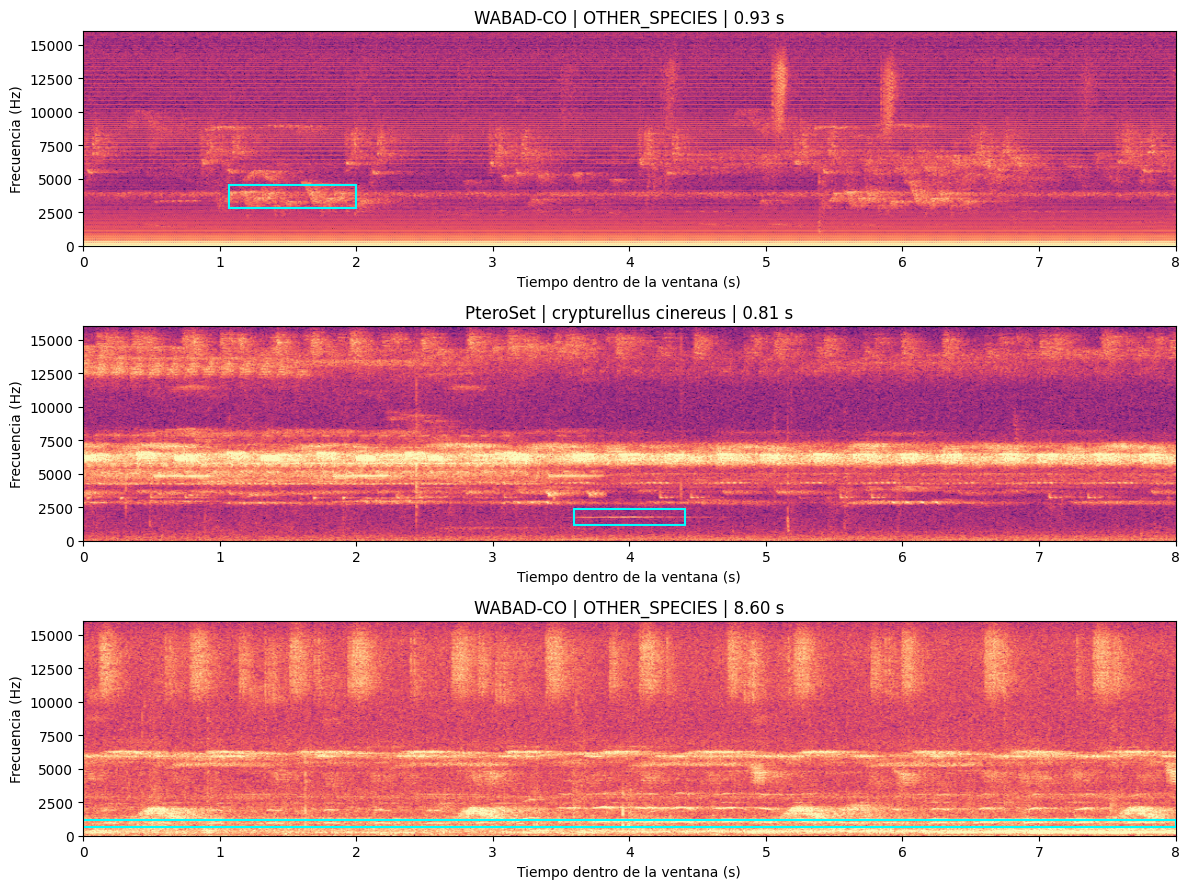

In [19]:
import soundfile as sf
from scipy.signal import stft
from matplotlib.patches import Rectangle

catalogo = train.merge(grabaciones[["recording_uid", "duration_sec"]], on="recording_uid", validate="many_to_one")
casos = [("WABAD-CO", 0.5, 2.0), ("PteroSet", 0.5, 2.0), ("WABAD-CO", 8.0, 30.0)]
muestras = []

for fuente, minimo, maximo in casos:
    candidatos = catalogo.loc[(catalogo["dataset"] == fuente) & (catalogo["duracion_s"] >= minimo) & (catalogo["duracion_s"] < maximo)]
    muestras.append(candidatos.sort_values(["duration_sec", "event_id"]).iloc[0])

fig, ejes = plt.subplots(len(muestras), 1, figsize=(12, 9))
for ax, fila in zip(ejes, muestras):
    ruta = str(fila["normalized_path"]).replace("\\", "/")
    if not ruta.startswith("DATASET_PROYECTO/"):
        ruta = f"DATASET_PROYECTO/{ruta}"

    archivo = Path(kagglehub.dataset_download( DATASET, path=ruta, output_dir=str(BASE_LOCAL)))

    with sf.SoundFile(archivo) as audio:
        fs = audio.samplerate
        duracion = len(audio) / fs
        centro = (fila["t_min"] + fila["t_max"]) / 2
        inicio = np.clip(centro - 4, 0, max(duracion - 8, 0))
        audio.seek(int(inicio * fs))
        senal = audio.read(int(8 * fs), dtype="float32")

    frecuencias, tiempos, z = stft(senal, fs=fs, nperseg=1024, noverlap=768, boundary=None)
    db = 20 * np.log10(np.maximum(np.abs(z), 1e-8))
    vmax = np.percentile(db, 99)
    ax.imshow(db, origin="lower", aspect="auto", extent=[0, len(senal) / fs, frecuencias[0], frecuencias[-1]], cmap="magma", vmin=vmax - 80, vmax=vmax)
    t0 = max(fila["t_min"] - inicio, 0)
    t1 = min(fila["t_max"] - inicio, len(senal) / fs)
    ax.add_patch(Rectangle( (t0, fila["f_min"]), t1 - t0, fila["f_max"] - fila["f_min"], fill=False, edgecolor="cyan", linewidth=1.5))
    ax.set_title(f"{fila['dataset']} | {fila['class_label']} | {fila['duracion_s']:.2f} s")
    ax.set_xlabel("Tiempo dentro de la ventana (s)")
    ax.set_ylabel("Frecuencia (Hz)")

plt.tight_layout()
plt.show()

**Resultados:** Las ventanas de 8 segundos contienen completamente el 92,55 % de los eventos analizados, frente al 82,70 % de las ventanas de 4 segundos. Sin embargo, las ventanas más largas presentan mayor solapamiento temporal con anotaciones de otras especies (59,02 % frente a 50,07 %).

La inspección visual confirma que las vocalizaciones pueden ocupar regiones pequeñas del espectrograma y que algunos eventos exceden la ventana de 8 segundos. Por ello, se propone preparar recortes centrados en las regiones anotadas, conservando contexto acústico y tratando separadamente los eventos de duración extrema.

## Inspección acústica de anotaciones extensas

Se examinan diferentes fragmentos de una anotación prolongada para investigar si representa una vocalización continua o un intervalo de actividad acústica. Esta revisión orientará el tratamiento de los eventos largos durante la preparación del clasificador.

100%|██████████| 111M/111M [00:03<00:00, 36.5MB/s]


Evento: Peru::13744
Especie: crypturellus soui
Fuente: Peru
Duracion anotada: 596.7 s


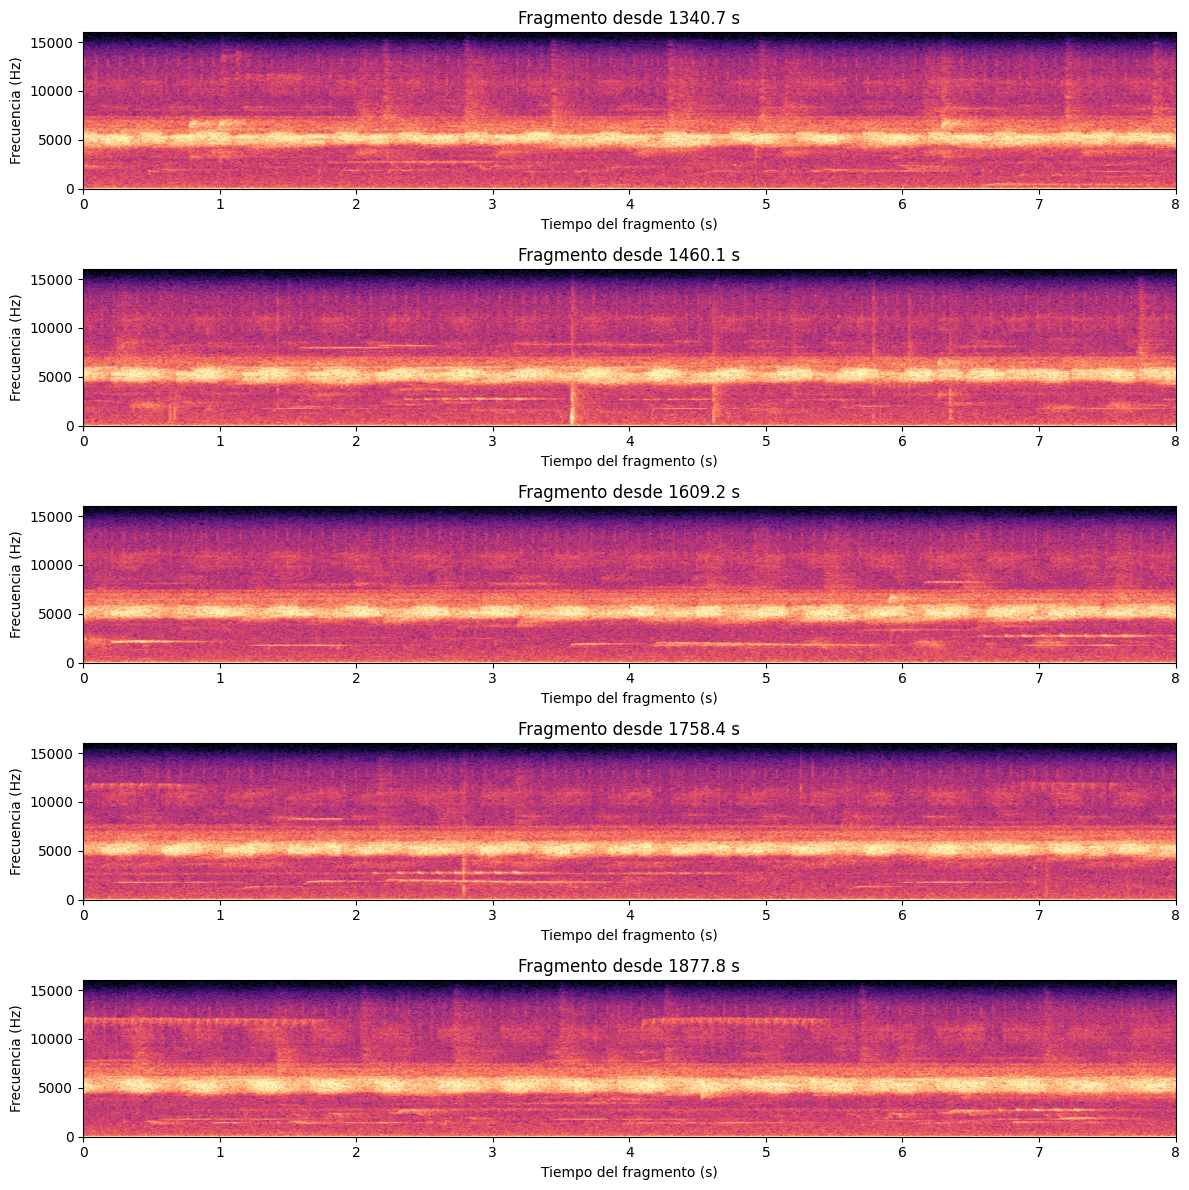

Escuchar fragmento desde 1340.7 s


Escuchar fragmento desde 1460.1 s


Escuchar fragmento desde 1609.2 s


Escuchar fragmento desde 1758.4 s


Escuchar fragmento desde 1877.8 s


In [20]:
import soundfile as sf
from scipy.signal import stft
from IPython.display import Audio, display

candidatos = train.loc[(train["duracion_s"] > 60) & (train["class_code"] != 0)]
evento = candidatos.nlargest(1, "duracion_s").iloc[0]
ruta = str(evento["normalized_path"]).replace("\\", "/")
if not ruta.startswith("DATASET_PROYECTO/"):
    ruta = f"DATASET_PROYECTO/{ruta}"

archivo = Path(kagglehub.dataset_download( DATASET, path=ruta, output_dir=str(BASE_LOCAL)))

print("Evento:", evento["event_id"])
print("Especie:", evento["class_label"])
print("Fuente:", evento["dataset"])
print("Duracion anotada:", round(evento["duracion_s"], 2), "s")

fragmentos = []
with sf.SoundFile(archivo) as audio:
    fs = audio.samplerate
    duracion_audio = len(audio) / fs
    for proporcion in (0.05, 0.25, 0.50, 0.75, 0.95):
        centro = evento["t_min"] + proporcion * evento["duracion_s"]
        inicio = np.clip(centro - 4, 0, max(duracion_audio - 8, 0))
        audio.seek(round(inicio * fs))
        senal = audio.read(round(8 * fs), dtype="float32", always_2d=True)
        senal = senal.mean(axis=1)
        fragmentos.append((inicio, senal))

fig, ejes = plt.subplots(5, 1, figsize=(12, 12))
for ax, (inicio, senal) in zip(ejes, fragmentos):
    frecuencias, tiempos, z = stft(senal, fs=fs, nperseg=1024, noverlap=768, boundary=None)
    db = 20 * np.log10(np.maximum(np.abs(z), 1e-8))
    vmax = np.percentile(db, 99)
    ax.imshow(db, origin="lower", aspect="auto", extent=[0, len(senal) / fs, frecuencias[0], frecuencias[-1]], cmap="magma", vmin=vmax - 80, vmax=vmax)
    ax.set_title(f"Fragmento desde {inicio:.1f} s")
    ax.set_xlabel("Tiempo del fragmento (s)")
    ax.set_ylabel("Frecuencia (Hz)")

plt.tight_layout()
plt.show()

for inicio, senal in fragmentos:
    print(f"Escuchar fragmento desde {inicio:.1f} s")
    display(Audio(senal, rate=fs))

### Solapamiento entre anotaciones de diferentes especies

Se cuantifica la intersección temporal y frecuencial de las anotaciones de especies distintas dentro de una misma grabación. Se compara el resultado incluyendo y excluyendo anotaciones extremadamente largas para determinar su influencia sobre los posibles conflictos de clasificación.

In [21]:
resultados_solapes = []

for uid, grupo in train.groupby("recording_uid", sort=False):
    t0 = grupo["t_min"].to_numpy()
    t1 = grupo["t_max"].to_numpy()
    f0 = grupo["f_min"].to_numpy()
    f1 = grupo["f_max"].to_numpy()
    codigos = grupo["class_code"].to_numpy()
    duraciones = grupo["duracion_s"].to_numpy()
    for i in range(len(grupo)):
        if duraciones[i] > 60:
            continue

        inter_t = np.maximum(np.minimum(t1[i], t1) - np.maximum(t0[i], t0), 0)
        inter_f = np.maximum(np.minimum(f1[i], f1) - np.maximum(f0[i], f0), 0)
        area = (t1[i] - t0[i]) * (f1[i] - f0[i])
        solapes = inter_t * inter_f / area
        otras = codigos != codigos[i]
        sin_largas = otras & (duraciones <= 60)
        solo_objetivo = sin_largas & (codigos != 0) & (codigos[i] != 0)
        resultados_solapes.append({
            "event_id": grupo.iloc[i]["event_id"],
            "recording_uid": uid,
            "dataset": grupo.iloc[i]["dataset"],
            "class_label": grupo.iloc[i]["class_label"],
            "class_code": codigos[i],
            "solape_total": float(solapes[otras].max()) if otras.any() else 0.0,
            "solape_sin_largas": float(solapes[sin_largas].max()) if sin_largas.any() else 0.0,
            "solape_solo_objetivo": float(solapes[solo_objetivo].max()) if solo_objetivo.any() else 0.0
        })

solapes_df = pd.DataFrame(resultados_solapes)

metricas = []

for nombre, columna, filtro in [("Todas las clases", "solape_total", solapes_df["class_code"] >= 0),("Sin eventos largos", "solape_sin_largas",solapes_df["class_code"] >= 0),("Solo especies objetivo", "solape_solo_objetivo", solapes_df["class_code"] != 0)]:
    valores = solapes_df.loc[filtro, columna]
    metricas.append({
        "escenario": nombre,
        "eventos": len(valores),
        "con_solape_pct": 100 * (valores > 0).mean(),
        "solape_10_pct": 100 * (valores >= 0.10).mean(),
        "solape_50_pct": 100 * (valores >= 0.50).mean()
    })

resumen_solapes = pd.DataFrame(metricas)
print("Resumen de solapamientos")
display(resumen_solapes.round(2))

por_fuente = solapes_df.groupby("dataset").agg(eventos=("event_id", "size"), solape_total_pct=("solape_total", lambda x: 100 * (x > 0).mean()),
                                               solape_sin_largas_pct=("solape_sin_largas", lambda x: 100 * (x > 0).mean()),
                                               solape_importante_pct=("solape_sin_largas", lambda x: 100 * (x >= 0.10).mean()))

print("Solapamientos por fuente")
display(por_fuente.round(2))
por_clase = (solapes_df.groupby("class_label").agg(eventos=("event_id", "size"), solape_10_pct=("solape_sin_largas", lambda x: 100 * (x >= 0.10).mean())).sort_values("solape_10_pct", ascending=False))
print("Clases con mayor solapamiento")
display(por_clase.head(12).round(2))
solapes_df.to_csv(DIR_EDA / "solapamientos_eventos.csv", index=False)
resumen_solapes.to_csv(DIR_EDA / "resumen_solapamientos.csv", index=False)

Resumen de solapamientos


,escenario,eventos,con_solape_pct,solape_10_pct,solape_50_pct
0,Todas las clases,17265,22.66,16.32,6.53
1,Sin eventos largos,17265,20.57,14.20,5.43
2,Solo especies objetivo,9222,16.22,11.19,4.38


Solapamientos por fuente


,eventos,solape_total_pct,solape_sin_largas_pct,solape_importante_pct
dataset,,,,
Col-CR,2101,10.52,10.28,6.66
Peru,3929,42.17,33.09,24.03
PteroSet,4771,10.92,10.92,6.43
WABAD-CO,6464,23.42,23.42,16.41


Clases con mayor solapamiento


,eventos,solape_10_pct
class_label,,
turdus leucomelas,137,45.26
synallaxis azarae,206,45.15
patagioenas plumbea,185,33.51
myiarchus tuberculifer,186,30.11
tyrannus melancholicus,226,27.88
crypturellus soui,155,27.74
campylorhynchus turdinus,740,25.95
ramphastos tucanus,179,25.14
cantorchilus leucotis,614,25.08


## Conclusiones del EDA

El análisis exploratorio identificó un desbalance considerable entre las 31 clases, con predominio de OTHER_SPECIES (46,5 % de los eventos de entrenamiento), además de una representación limitada de algunas especies en validación.

Se observaron diferencias importantes en las duraciones y bandas frecuenciales de las anotaciones, así como concentración de determinadas especies en pocas grabaciones o fuentes de datos.

La inspección de anotaciones extensas evidenció que no es posible asumir presencia continua de una especie durante todo un intervalo. Por ello, las 87 anotaciones de entrenamiento superiores a 60 segundos se marcarán para revisión y se excluirán provisionalmente del entrenamiento.

El análisis de solapamiento tiempo-frecuencia identificó posibles conflictos entre especies. Estos eventos se conservarán inicialmente, registrando su grado de superposición para analizar su influencia durante la evaluación.

Se mantendrán las 31 clases y las particiones originales. La selección de duración de entrada, márgenes, normalización y estrategias de balanceo se realizará posteriormente mediante decisiones de preprocesamiento y experimentos de validación.

Con estos hallazgos se considera finalizada la etapa de análisis exploratorio y se procede a la preparación del conjunto de datos para clasificación.